# Play with CoLoRe outputs (including quasar densities and CMB lensing)

In [1]:
import os
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt
from astropy.io import fits

In [2]:
# folder with nfiles containing the galaxy densities, and the CMB lensing map
box_dir='/global/cfs/cdirs/desicollab/users/lauracdp/cmb_lensing_box/test_box-0/results'
nfiles=32

### Read the galaxy (quasars) density maps

In [3]:
def read_file(box_dir, ipix):
    fname = box_dir + '/out_srcs_s1_{}.fits'.format(ipix)
    cat = fits.open(fname)[1].data
    ra = cat['RA']
    dec = cat['DEC']
    z_no_rsd = cat['Z_COSMO']
    dz_rsd = cat['DZ_RSD']
    ngal = len(ra)
    info = {'ngal':ngal, 'ra': ra, 'dec': dec, 'z_no_rsd': z_no_rsd, 'dz_rsd': dz_rsd}
    return info

In [4]:
info = read_file(box_dir, 0)

In [5]:
def get_global_info(box_dir, nfiles):
    # collect information from each file
    info = {}
    for ipix in range(nfiles):
        ipix_info = read_file(box_dir, ipix)
        info[ipix] = ipix_info
    # concatenate lists
    ra_list = [ipix_info['ra'] for ipix_info in info.values()]
    ra = np.concatenate(ra_list, axis=0)
    dec_list = [ipix_info['dec'] for ipix_info in info.values()]
    dec = np.concatenate(dec_list, axis=0)
    z_no_rsd_list = [ipix_info['z_no_rsd'] for ipix_info in info.values()]
    z_no_rsd = np.concatenate(z_no_rsd_list, axis=0)
    dz_rsd_list = [ipix_info['dz_rsd'] for ipix_info in info.values()]
    dz_rsd = np.concatenate(dz_rsd_list, axis=0)
    # put everything into a dictionary
    return {'ra': ra, 'dec': dec, 'z_no_rsd': z_no_rsd, 'dz_rsd': dz_rsd}

In [6]:
info = get_global_info(box_dir=box_dir, nfiles=nfiles)

Text(0.5, 0, 'z')

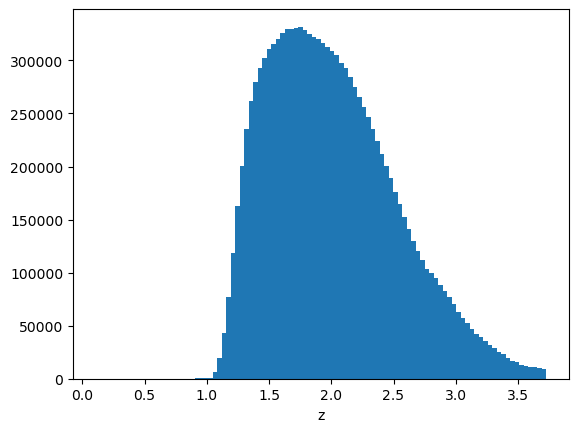

In [7]:
plt.hist(info['z_no_rsd'], bins=100)
plt.xlabel('z')

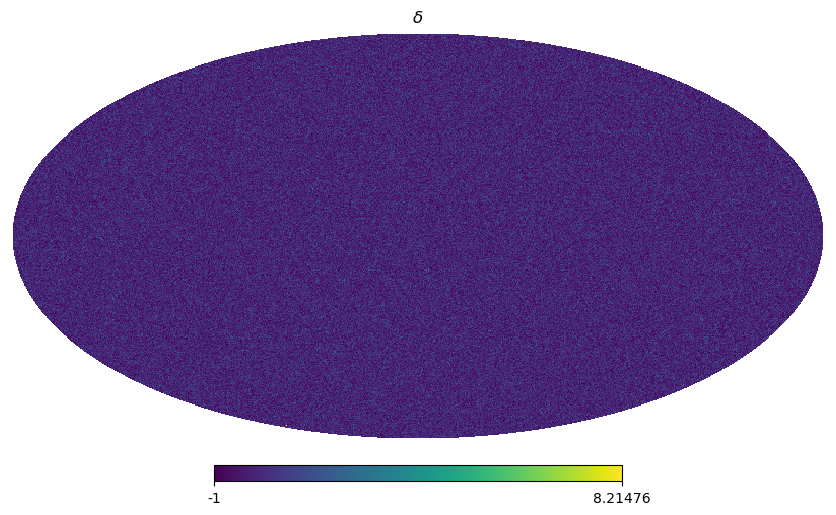

In [8]:
nside = 512
npix = hp.nside2npix(nside)
ipix = hp.ang2pix(nside, info['ra'], info['dec'], lonlat=True)
ncount = np.bincount(ipix, minlength=npix)
nmean = np.mean(ncount)
delta_g = ncount/nmean-1
hp.mollview(delta_g, title=r'$\delta$')
#goodpix = ncount > 0
#dzrsd = np.bincount(ipix, minlength=npix, weights=cat['DZ_RSD'])
#dzrsd[goodpix] = dzrsd[goodpix] / ncount[goodpix]
#hp.mollview(dzrsd, title=r'$\Delta z_{\rm RSD}$')

12289649


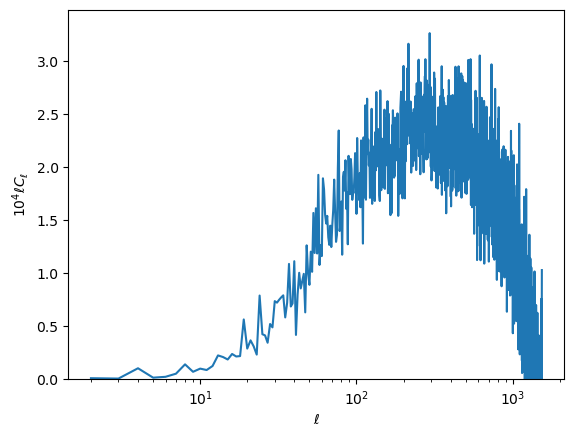

In [9]:
cl_gg = hp.anafast(delta_g)
ell = np.arange(len(cl_gg))

# compute shot noise
Ntot = np.sum(ncount)
print(Ntot)
nbar = Ntot / (4*np.pi)
cl_shot = 1.0 / nbar

plt.semilogx(ell[2:], 1e4*ell[2:]*(cl_gg[2:]-cl_shot))
plt.xlabel(r'$\ell$')
plt.ylabel(r'$10^4 \ell C_\ell$')
plt.ylim(bottom=0)
plt.show()

### Read CMB kappa maps

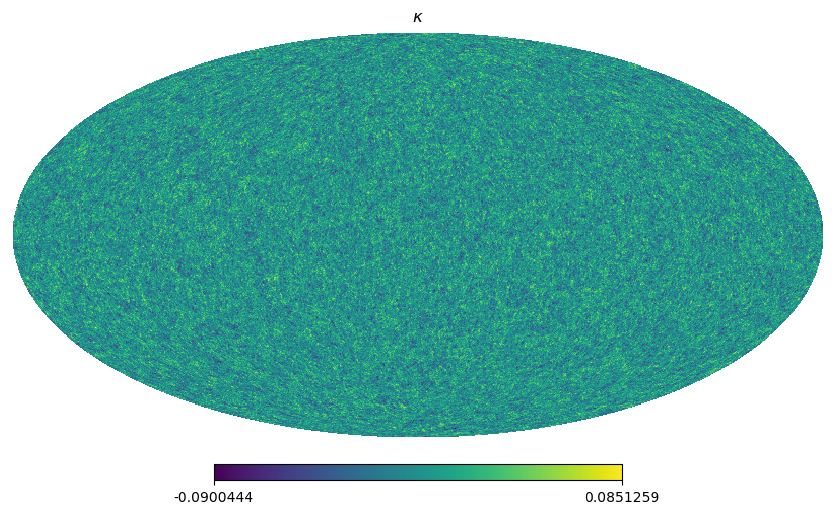

In [10]:
m_k = hp.read_map(box_dir+'/out_kappa_z000.fits')
hp.mollview(m_k, title=r'$\kappa$')

Text(0.5, 0, '$\\kappa$')

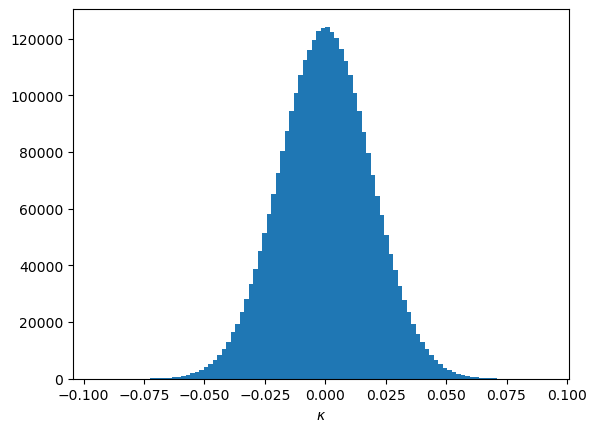

In [11]:
plt.hist(m_k,bins=100)
plt.xlabel(r'$\kappa$')

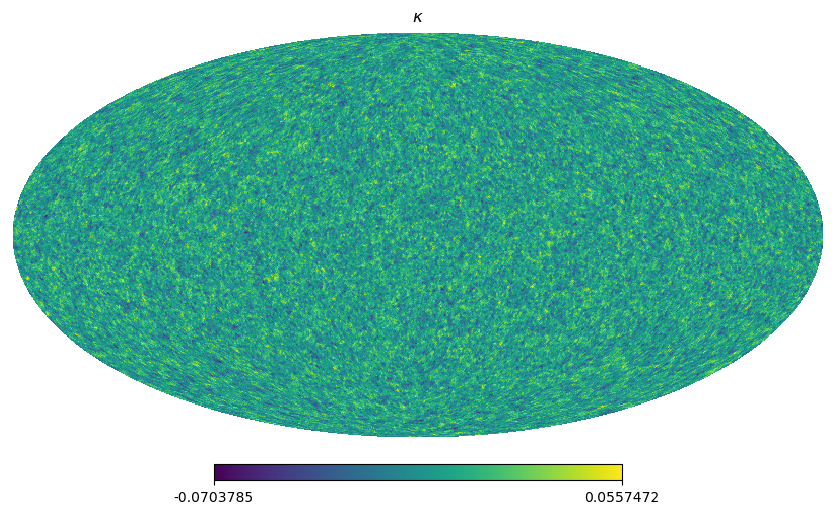

In [12]:
# try to get a lower resolution version of the map
nside_lr = 128
m_lr = hp.ud_grade(m_k, nside_out=nside_lr)
hp.mollview(m_lr, title=r'$\kappa$')

### Compute the Cells from a Healpix map

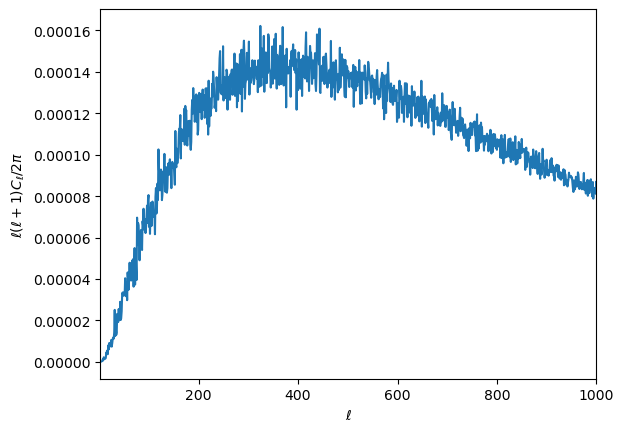

In [13]:
# Compute Cl
cl_kk = hp.anafast(m_k)

# Multipole values
ell = np.arange(len(cl_kk))

# Plot Dl = ell(ell+1)Cl / 2pi  (standard CMB convention)
dl = ell * (ell + 1) * cl_kk / (2 * np.pi)

plt.plot(ell, dl)
plt.xlabel(r'$\ell$')
plt.ylabel(r'$\ell(\ell+1)C_\ell / 2\pi$')
plt.xlim(2, 1000)
plt.show()

### Compute the cross-correlation of CMB lensing and galaxies (quasars)

In [14]:
cl_kg = hp.anafast(m_k, delta_g)

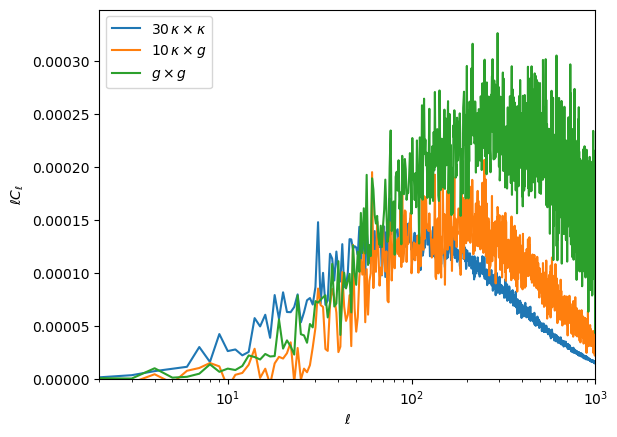

In [15]:
plt.semilogx(ell, 30 * ell * cl_kk, label=r'$30 \, \kappa \times \kappa$')
plt.semilogx(ell, 10 * ell * cl_kg, label=r'$10 \, \kappa \times g$')
plt.semilogx(ell, 1 *  ell * (cl_gg-cl_shot), label=r'$g \times g$')
plt.xlabel(r'$\ell$')
plt.ylabel(r'$\ell C_\ell$')
plt.xlim(2, 1000)
plt.ylim(bottom=0)
plt.legend()

## Ask Chat-GPT to be fancier with binning and errors

In [16]:
def compute_cls_and_variances(cmb_map, gal_counts, lmax=None, bin_width=None):

    # Convert galaxy counts → overdensity
    mean_counts = np.mean(gal_counts)
    delta_g = (gal_counts - mean_counts) / mean_counts

    # Compute spectra
    cl_tt = hp.anafast(cmb_map, lmax=lmax)
    cl_gg_tot = hp.anafast(delta_g, lmax=lmax)
    cl_tg = hp.anafast(cmb_map, delta_g, lmax=lmax)

    ell = np.arange(len(cl_tt))

    # Shot noise (full sky)
    Ntot = np.sum(gal_counts)
    nbar = Ntot / (4*np.pi)
    N_gg = 1.0 / nbar

    # no CMB lensing noise here
    N_tt = 0

    # Signal-only galaxy spectrum
    cl_gg = cl_gg_tot - N_gg

    # Variances (full sky: fsky = 1)
    var_tt = 2.0 * (cl_tt + N_tt)**2 / (2*ell + 1)
    var_gg = 2.0 * (cl_gg + N_gg)**2 / (2*ell + 1)
    var_tg = (
        cl_tg**2 +
        (cl_tt + N_tt)*(cl_gg + N_gg)
    ) / (2*ell + 1)

    # Optional binning
    if bin_width is not None:
        def bin_array(arr):
            nb = len(arr) // bin_width
            return np.array([
                np.mean(arr[i*bin_width:(i+1)*bin_width])
                for i in range(nb)
            ])
            
        # I'm being lazy here
        ell = bin_array(ell)
        cl_tt = bin_array(cl_tt)
        cl_gg = bin_array(cl_gg)
        cl_tg = bin_array(cl_tg)
        var_tt = bin_array(var_tt) / bin_width
        var_gg = bin_array(var_gg) / bin_width
        var_tg = bin_array(var_tg) / bin_width

    return ell, cl_tt, cl_gg, cl_tg, var_tt, var_gg, var_tg


In [17]:
ell, cl_kk, cl_gg, cl_kg, var_kk, var_gg, var_kg = compute_cls_and_variances(m_k, ncount, lmax=None, bin_width=16)

In [18]:
def plot_cls(ell, cl_tt, cl_gg, cl_tg,
             var_tt, var_gg, var_tg, savefig=None):

    # Remove monopole/dipole
    m = ell >= 2
    ell = ell[m]

    cl_tt = cl_tt[m]
    cl_gg = cl_gg[m]
    cl_tg = cl_tg[m]

    sigma_tt = np.sqrt(var_tt[m])
    sigma_gg = np.sqrt(var_gg[m])
    sigma_tg = np.sqrt(var_tg[m])

    # Convert to D_ell
    prefac = ell * (ell + 1) / (2*np.pi)

    Dl_tt = prefac * cl_tt
    Dl_gg = prefac * cl_gg
    Dl_tg = prefac * cl_tg

    err_tt = prefac * sigma_tt
    err_gg = prefac * sigma_gg
    err_tg = prefac * sigma_tg

    # --- Plot ---
    fig, ax = plt.subplots(3, 1, figsize=(7, 10), sharex=True)

    ax[0].errorbar(ell, Dl_tt, yerr=err_tt, fmt='o', ms=3)
    ax[0].set_ylabel(r'$D_\ell^{\kappa \kappa}$')
    ax[0].set_title('Angular Power Spectra')

    ax[1].errorbar(ell, Dl_gg, yerr=err_gg, fmt='o', ms=3)
    ax[1].set_ylabel(r'$D_\ell^{gg}$')

    ax[2].errorbar(ell, Dl_tg, yerr=err_tg, fmt='o', ms=3)
    ax[2].set_ylabel(r'$D_\ell^{\kappa g}$')
    ax[2].set_xlabel(r'$\ell$')

    plt.tight_layout()
    if savefig:
        plt.savefig(savefig)

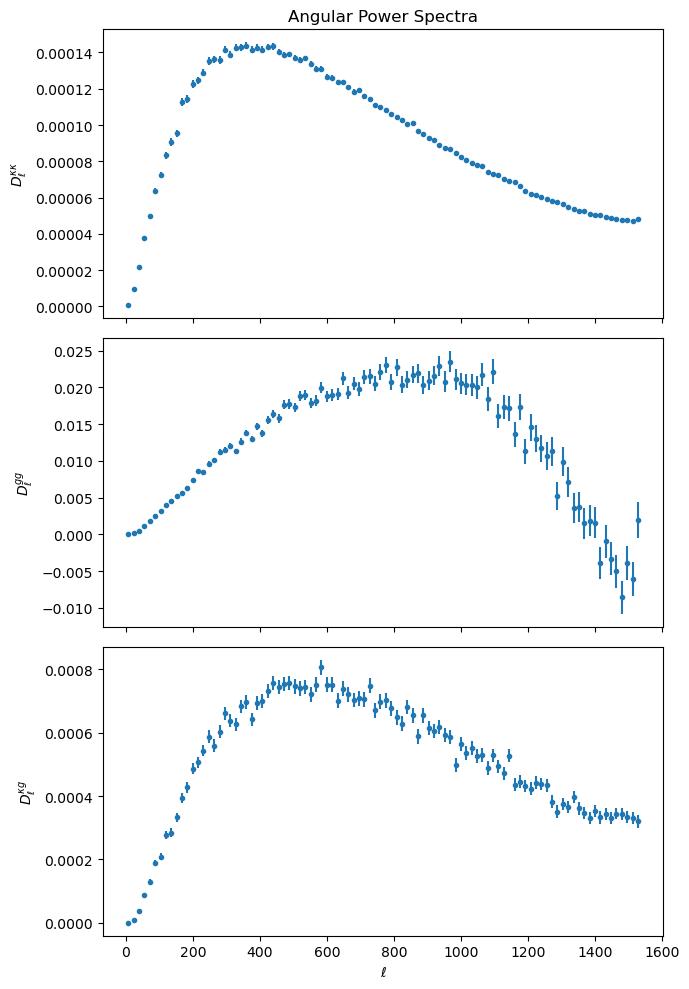

In [19]:
plot_cls(ell, cl_kk, cl_gg, cl_kg, var_kk, var_gg, var_kg, savefig='cmb_gal.png')